# House Price Prediction Using Linear Regression

**Internship:** Oasis Infobyte Data Analytics Internship  
**Level:** Level 2 — Task 1  
**Author:** Prajwal Poojary

## Project Overview

This project develops a machine learning model to predict residential house sale prices using the Ames Housing dataset. The workflow includes data exploration, missing-value handling, categorical encoding, model training, evaluation, and visualization.

## Objectives

- Explore the dataset and identify missing values.
- Prepare numerical and categorical features for modelling.
- Train a Linear Regression model.
- Evaluate predictions using MAE, RMSE, and R².
- Visualize prediction errors and interpret model coefficients.

In [2]:
%pip install liac-arff

Defaulting to user installation because normal site-packages is not writeable
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11781 sha256=a1955e0fd14bb5a9571c1a0c27c4cf0736ee34b4418d5f93e6ce2554dab8053b
  Stored in directory: c:\users\pooja\appdata\local\pip\cache\wheels\93\f3\5b\658a9bddee916a5f4b84bdc1a4e0fabd22fb17947c2c9542e6
Successfully built liac-arff
Note: you may need to restart the kernel to use updated packages.


  DEPRECATION: Building 'liac-arff' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'liac-arff'. Discussion can be found at https://github.com/pypa/pip/issues/6334

[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import arff
import pandas as pd
from pathlib import Path

files = list(Path(".").glob("*.arff"))

if not files:
    print("No ARFF file found. Check your project folder.")
else:
    with open(files[0], "r", encoding="utf-8") as file:
        dataset = arff.load(file)

    df = pd.DataFrame(
        dataset["data"],
        columns=[attribute[0] for attribute in dataset["attributes"]]
    )

    df.to_csv("Ames_Housing.csv", index=False)

    print("Conversion successful!")
    print("Source file:", files[0].name)
    print("Dataset shape:", df.shape)
    print("First five rows:")
    display(df.head())
    print("Column names:")
    print(df.columns.tolist())

Conversion successful!
Source file: dataset.arff
Dataset shape: (1460, 81)
First five rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,12,2008,WD,Normal,250000


Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolA

In [4]:
from pathlib import Path

csv_path = Path("Ames_Housing.csv")

if csv_path.exists():
    print("CSV file saved successfully!")
    print("File location:", csv_path.resolve())
    print(f"File size: {csv_path.stat().st_size / 1024:.2f} KB")
else:
    print("CSV not found. Check the notebook's working folder.")

CSV file saved successfully!
File location: C:\OIBSIP\Level_2\Task_1_House_Price_Prediction\Ames_Housing.csv
File size: 445.58 KB


Dataset shape: (1460, 81)

Data types:
object     43
int64      35
float64     3
Name: count, dtype: int64

Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

SalePrice summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


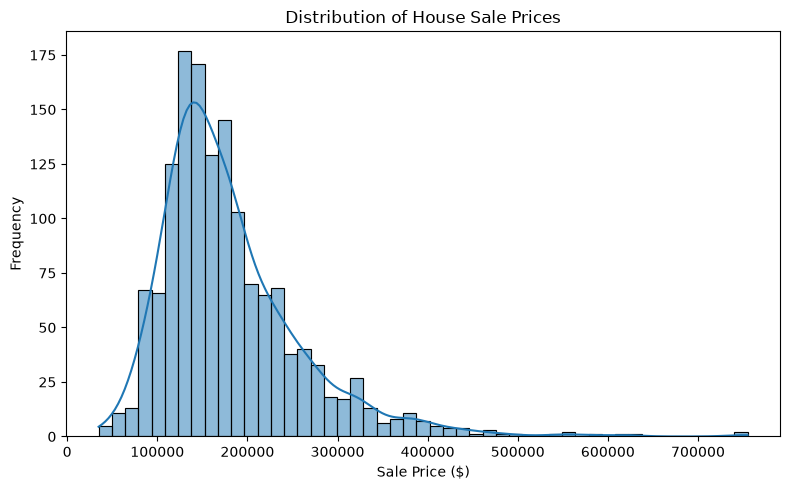

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the converted dataset
df = pd.read_csv("Ames_Housing.csv")

# Dataset overview
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes.value_counts())

# Missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nColumns with missing values:")
print(missing)

# Summary of the target variable
print("\nSalePrice summary:")
print(df["SalePrice"].describe())

# Distribution of house sale prices
plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [7]:
# Separate columns by data type
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

# Display missing values with their percentages
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary)

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("Total columns with missing values:", len(missing_summary))

,Missing_Count,Missing_Percentage,Data_Type
PoolQC,1453,99.52,object
MiscFeature,1406,96.30,object
Alley,1369,93.77,object
Fence,1179,80.75,object
MasVnrType,872,59.73,object
FireplaceQu,690,47.26,object
LotFrontage,259,17.74,float64
GarageType,81,5.55,object
GarageYrBlt,81,5.55,float64
GarageFinish,81,5.55,object


Numerical columns: 38
Categorical columns: 43
Total columns with missing values: 19


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Separate features and target
X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Target:", y.name)

Training rows: 1168
Testing rows: 292
Numerical features: 36
Categorical features: 43
Target: SalePrice


In [9]:
# Train the model
model.fit(X_train, y_train)

# Predict prices for the test set
y_pred = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression — Model Evaluation")
print("-" * 40)
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²:    {r2:.4f}")
print(f"R² (%): {r2 * 100:.2f}%")

Linear Regression — Model Evaluation
----------------------------------------
MAE:  $20,466.13
RMSE: $31,294.99
R²:    0.8723
R² (%): 87.23%


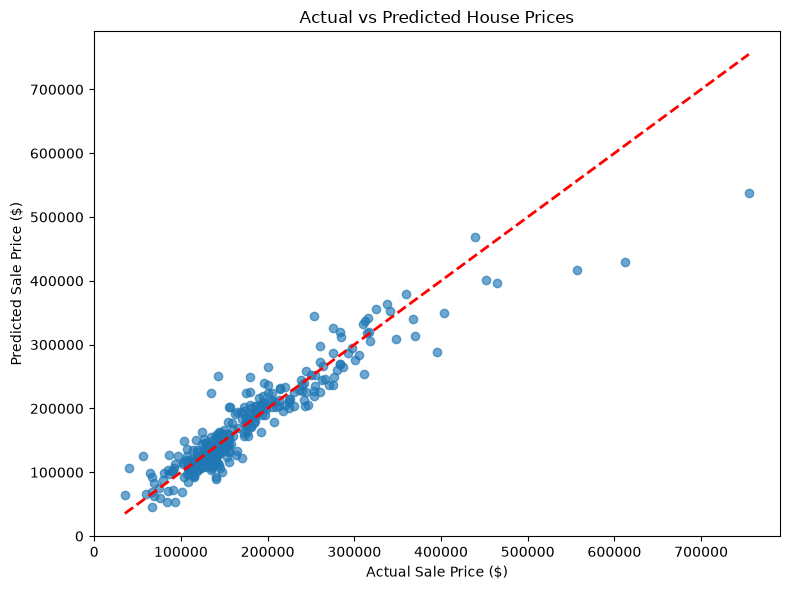

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.65)

# Reference line: perfect predictions
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], "r--", linewidth=2)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.tight_layout()
plt.show()

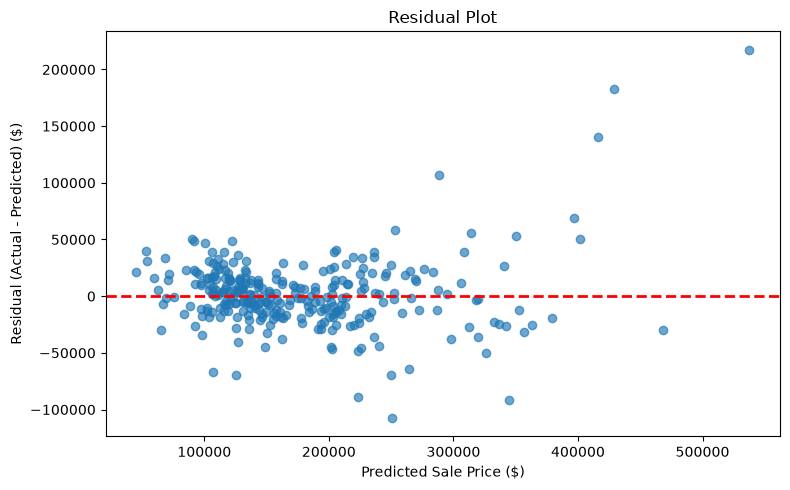

In [11]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.65)
plt.axhline(y=0, color="red", linestyle="--", linewidth=2)

plt.title("Residual Plot")
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual (Actual - Predicted) ($)")
plt.tight_layout()
plt.show()


In [12]:

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get coefficients from the trained Linear Regression model
coefficients = model.named_steps["regressor"].coef_

# Put feature names and coefficients into a table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Show the 10 largest positive and negative coefficients
print("Top 10 Positive Coefficients:")
display(
    feature_importance.nlargest(10, "Coefficient")
)

print("Top 10 Negative Coefficients:")
display(
    feature_importance.nsmallest(10, "Coefficient")
)


Top 10 Positive Coefficients:


,Feature,Coefficient
78,cat__Neighborhood_NoRidge,41901.268218
85,cat__Neighborhood_StoneBr,39134.933544
259,cat__PoolQC_Ex,28020.792433
79,cat__Neighborhood_NridgHt,24777.963772
134,cat__Exterior1st_BrkFace,23198.043843
153,cat__Exterior2nd_ImStucc,21429.506595
180,cat__BsmtQual_Ex,20061.527068
221,cat__KitchenQual_Ex,19445.880060
50,cat__LandContour_HLS,18920.803465
69,cat__Neighborhood_Crawfor,16885.159464


Top 10 Negative Coefficients:


,Feature,Coefficient
124,cat__RoofMatl_ClyTile,-29057.711990
261,cat__PoolQC_Gd,-24972.333443
101,cat__Condition2_PosN,-24387.894785
74,cat__Neighborhood_Mitchel,-21248.184226
49,cat__LandContour_Bnk,-20468.188112
70,cat__Neighborhood_Edwards,-17223.304884
47,cat__LotShape_IR3,-15412.090547
71,cat__Neighborhood_Gilbert,-14890.232469
77,cat__Neighborhood_NWAmes,-14294.379434
75,cat__Neighborhood_NAmes,-13055.799494


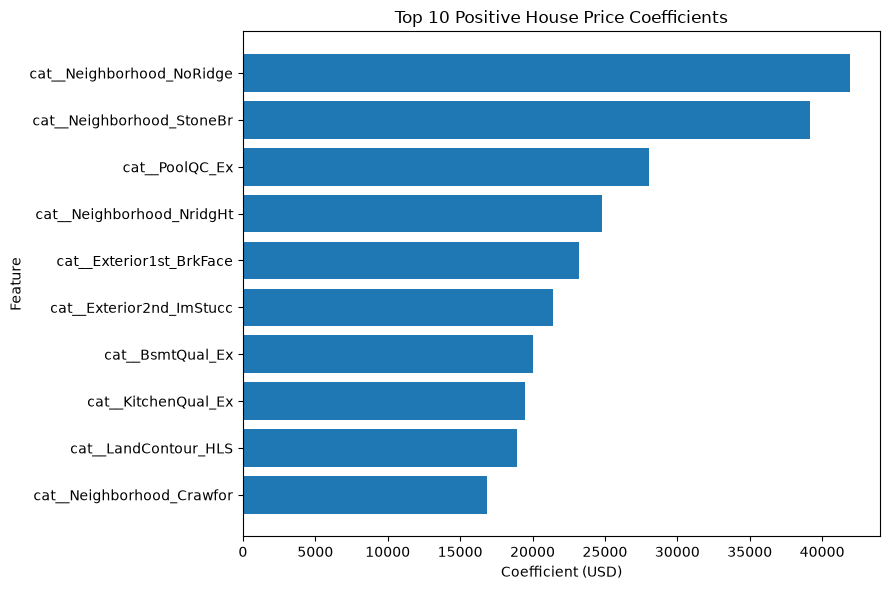

In [13]:

top_positive = feature_importance.nlargest(10, "Coefficient")
top_positive = top_positive.sort_values("Coefficient")

plt.figure(figsize=(9, 6))
plt.barh(top_positive["Feature"], top_positive["Coefficient"])
plt.title("Top 10 Positive House Price Coefficients")
plt.xlabel("Coefficient (USD)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [14]:

comparison = pd.DataFrame({
    "Actual Price ($)": y_test,
    "Predicted Price ($)": y_pred
})

comparison["Prediction Error ($)"] = (
    comparison["Actual Price ($)"] -
    comparison["Predicted Price ($)"]
)

display(comparison.head(10).round(2))


,Actual Price ($),Predicted Price ($),Prediction Error ($)
892,154500,151971.20,2528.80
1105,325000,356441.14,-31441.14
413,115000,95590.88,19409.12
522,159000,177919.64,-18919.64
1036,315500,342171.21,-26671.21
614,75500,59615.32,15884.68
218,311500,253448.95,58051.05
1160,146000,153388.04,-7388.04
649,84500,53796.96,30703.04
887,135500,149553.68,-14053.68
